In [1]:
import os
os.environ['TF_USE_LEGACY_KERAS'] = '1'

In [2]:
import tensorflow as tf
import tensorflow_hub as hub
import tensorflow_text as text

In [3]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/Datasets/spam.csv")
df.head(5)

,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [4]:
df.groupby('Category').describe()

Message                                                            \
           count unique                                                top   
Category                                                                     
ham         4825   4516                             Sorry, I'll call later   
spam         747    641  Please call our customer service representativ...   

               
         freq  
Category       
ham        30  
spam        4

In [5]:
df['Category'].value_counts()

,count
Category,
ham,4825
spam,747


In [6]:
print("Spam", round((747/4825)*100, 2), "%")

Spam 15.48 %


15% spam emails, 85% ham emails: This indicates class imbalance

In [7]:
df_spam = df[df['Category']=='spam']
df_spam.shape

(747, 2)

In [8]:
df_ham = df[df['Category']=='ham']
df_ham.shape

(4825, 2)

In [9]:
df_ham_downsampled = df_ham.sample(df_spam.shape[0])
df_ham_downsampled.shape

(747, 2)

In [10]:
df_balanced = pd.concat([df_spam, df_ham_downsampled])
df_balanced.shape

(1494, 2)

In [11]:
df_balanced['Category'].value_counts()

,count
Category,
spam,747
ham,747


In [12]:
df_balanced.sample(5)

,Category,Message
4663,ham,Ladies first and genus second k .
2804,spam,FreeMsg>FAV XMAS TONES!Reply REAL
5435,ham,I'm wif him now buying tix lar...
3828,spam,Congratulations U can claim 2 VIP row A Ticket...
5522,ham,Thats cool. I want to please you...


In [13]:
df_balanced['spam']=df_balanced['Category'].apply(lambda x: 1 if x=='spam' else 0)
df_balanced.sample(5)

,Category,Message,spam
4126,ham,May b approve panalam...but it should have mor...,0
1064,spam,We have new local dates in your area - Lots of...,1
3458,ham,Friendship poem: Dear O Dear U R Not Near But ...,0
5112,spam,December only! Had your mobile 11mths+? You ar...,1
1500,spam,"SMS. ac JSco: Energy is high, but u may not kn...",1


In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(df_balanced['Message'], df_balanced['spam'], stratify=df_balanced['spam'])

In [15]:
X_train.head(4)

,Message
1337,"Sweet, we may or may not go to 4U to meet carl..."
5189,ree entry in 2 a weekly comp for a chance to w...
3344,"I haven't forgotten you, i might have a couple..."
3328,what number do u live at? Is it 11?


In [16]:
bert_preprocess = hub.KerasLayer("https://www.kaggle.com/models/tensorflow/bert/TensorFlow2/en-uncased-preprocess/3")
bert_encoder = hub.KerasLayer("https://www.kaggle.com/models/tensorflow/bert/TensorFlow2/en-uncased-l-12-h-768-a-12/4")

In [17]:
def get_sentence_embedding(sentences):
    preprocessed_text = bert_preprocess(sentences)
    return bert_encoder(preprocessed_text)['pooled_output']

get_sentence_embedding([
    "500$ discount. hurry up",
    "john, are you up for a volleyball game tomorrow?"]
)

<tf.Tensor: shape=(2, 768), dtype=float32, numpy=
array([[-0.84351707, -0.51327264, -0.88845706, ..., -0.7474882 ,
        -0.75314736,  0.919645  ],
       [-0.8605658 , -0.5118305 , -0.9487119 , ..., -0.88074887,
        -0.7081549 ,  0.8742053 ]], dtype=float32)>

Get embeding vectors for few sample words. Compare them using cosine similarity.

In [18]:
e = get_sentence_embedding([
    "banana",
    "grapes",
    "mango",
    "jeff bezos",
    "elon musk",
    "bill gates"
]
)

In [19]:
e

<tf.Tensor: shape=(6, 768), dtype=float32, numpy=
array([[-0.7606915 , -0.14219376,  0.4960467 , ...,  0.4216536 ,
        -0.5322138 ,  0.80312145],
       [-0.86023206, -0.21242924,  0.49156895, ...,  0.39798048,
        -0.60506266,  0.8447164 ],
       [-0.7128859 , -0.15463893,  0.3840169 , ...,  0.35278746,
        -0.50991327,  0.73474085],
       [-0.82533497, -0.3555061 , -0.5906979 , ..., -0.01613776,
        -0.61417586,  0.872303  ],
       [-0.75041306, -0.2681259 , -0.26689523, ...,  0.02839481,
        -0.59380955,  0.79749805],
       [-0.78544325, -0.29949653,  0.41027546, ...,  0.5222549 ,
        -0.49573535,  0.8150746 ]], dtype=float32)>

In [20]:
from sklearn.metrics.pairwise import cosine_similarity

cosine_similarity([e[0]],[e[1]])

array([[0.9911087]], dtype=float32)

Values near to 1 means they are similar.
0 means they are very different. Above you can use comparing "banana" vs "grapes" you get 0.99 similarity as they both are fruits.

In [21]:
cosine_similarity([e[0]],[e[3]])

array([[0.8470379]], dtype=float32)

Comparing banana with jeff bezos you still get 0.84 but it is not as close as 0.99 that we got with grapes.

In [22]:
cosine_similarity([e[3]],[e[4]])

array([[0.9872033]], dtype=float32)

Jeff bezos and Elon musk are more similar than Jeff bezos and banana as shown above.

### Build Model
There are two types of models you can build in tensorflow.

1. Sequential
2. Functional

In [23]:
# Build the model
text_input = tf.keras.layers.Input(shape=(), dtype=tf.string, name='text')
preprocessed_text = bert_preprocess(text_input)
outputs = bert_encoder(preprocessed_text)

# Neural network layers
l = tf.keras.layers.Dropout(0.1, name="dropout")(outputs['pooled_output'])
l = tf.keras.layers.Dense(1, activation='sigmoid', name="output")(l)

# Construct final model
model = tf.keras.Model(inputs=[text_input], outputs=[l])

In [24]:
model.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 text (InputLayer)           [(None,)]                    0         []                            
                                                                                                  
 keras_layer (KerasLayer)    {'input_type_ids': (None,    0         ['text[0][0]']                
                             128),                                                                
                              'input_mask': (None, 128)                                           
                             , 'input_word_ids': (None,                                           
                              128)}                                                               
                                                                                              

In [25]:
len(X_train)

1120

In [26]:
METRICS = [
      tf.keras.metrics.BinaryAccuracy(name='accuracy'),
      tf.keras.metrics.Precision(name='precision'),
      tf.keras.metrics.Recall(name='recall')
]

model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=METRICS)

In [27]:
model.fit(X_train, y_train, epochs=10)

Epoch 1/10
35/35 [==============================] - 21s 286ms/step - loss: 0.6156 - accuracy: 0.6759 - precision: 0.6650 - recall: 0.7089
Epoch 2/10
35/35 [==============================] - 10s 290ms/step - loss: 0.5076 - accuracy: 0.8071 - precision: 0.7925 - recall: 0.8321
Epoch 3/10
35/35 [==============================] - 10s 294ms/step - loss: 0.4524 - accuracy: 0.8393 - precision: 0.8381 - recall: 0.8411
Epoch 4/10
35/35 [==============================] - 11s 319ms/step - loss: 0.4145 - accuracy: 0.8670 - precision: 0.8501 - recall: 0.8911
Epoch 5/10
35/35 [==============================] - 11s 304ms/step - loss: 0.3708 - accuracy: 0.8795 - precision: 0.8583 - recall: 0.9089
Epoch 6/10
35/35 [==============================] - 11s 302ms/step - loss: 0.3618 - accuracy: 0.8777 - precision: 0.8730 - recall: 0.8839
Epoch 7/10
35/35 [==============================] - 11s 316ms/step - loss: 0.3344 - accuracy: 0.8866 - precision: 0.8626 - recall: 0.9196
Epoch 8/10
35/35 [================

In [28]:
model.evaluate(X_test, y_test)

12/12 [==============================] - 5s 299ms/step - loss: 0.2684 - accuracy: 0.9278 - precision: 0.9167 - recall: 0.9412


[0.2683585286140442,
 0.9278075098991394,
 0.9166666865348816,
 0.9411764740943909]

In [29]:
y_predicted = model.predict(X_test)
y_predicted = y_predicted.flatten()

12/12 [==============================] - 4s 305ms/step


In [30]:
import numpy as np

y_predicted = np.where(y_predicted > 0.5, 1, 0)
y_predicted

array([0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0,
       1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0,
       0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 1,
       0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0,
       1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1,
       1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1,
       0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1,
       1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0,
       1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1,
       0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 1, 1, 1, 1,
       1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0,
       0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1,
       0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1,

In [31]:
from sklearn.metrics import confusion_matrix, classification_report

cm = confusion_matrix(y_test, y_predicted)
cm

array([[171,  16],
       [ 11, 176]])

Text(50.722222222222214, 0.5, 'Truth')

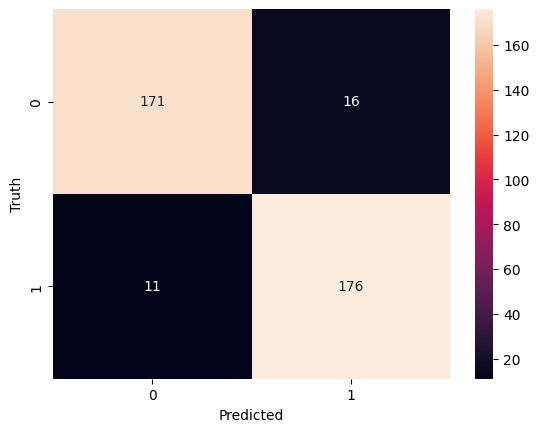

In [32]:
from matplotlib import pyplot as plt
import seaborn as sn
sn.heatmap(cm, annot=True, fmt='d')
plt.xlabel('Predicted')
plt.ylabel('Truth')

In [33]:
print(classification_report(y_test, y_predicted))

              precision    recall  f1-score   support

           0       0.94      0.91      0.93       187
           1       0.92      0.94      0.93       187

    accuracy                           0.93       374
   macro avg       0.93      0.93      0.93       374
weighted avg       0.93      0.93      0.93       374



In [34]:
# Inference
reviews = [
    'Enter a chance to win $5000, hurry up, offer valid until march 31, 2021',
    'You are awarded a SiPix Digital Camera! call 09061221061 from landline. Delivery within 28days. T Cs Box177. M221BP. 2yr warranty. 150ppm. 16 . p pÂ£3.99',
    'it to 80488. Your 500 free text messages are valid until 31 December 2005.',
    'Hey Sam, Are you coming for a cricket game tomorrow',
    "Why don't you wait 'til at least wednesday to see if you get your ."
]
model.predict(reviews)

1/1 [==============================] - 2s 2s/step


array([[0.81782836],
       [0.8480472 ],
       [0.79833186],
       [0.24336424],
       [0.08416133]], dtype=float32)